<a href="https://colab.research.google.com/github/AbirHossainApon/AbirHossainApon/blob/main/Mooc_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Complete MOOC Decline and Dropout Analysis Pipeline

This notebook runs the full analysis from raw course files to practical course-design recommendations. Run the cells from top to bottom. Before starting, change `DATA_ROOT` so that it points to the folder containing the course data.

The analysis studies how learner activity changes over time, identifies common engagement patterns, predicts early decline and final completion, and explains the model results. All generated files are saved in a separate output folder.



## 1. Setup and Configuration

This section prepares the notebook for the analysis. We define where the raw data is stored, choose the course to analyze, and create folders for the output files.

The data folder must contain four CSV files for the selected course: `activities.csv`, `activity_events.csv`, `grades.csv`, and `video_events.csv`. The notebook installs the required Python packages and imports the libraries used for data processing, statistics, machine learning, and visualisation.

The random seed is fixed so that model results are reproducible. This means that repeating the analysis with the same data should produce the same results.



### Notes

`DATA_ROOT` is combined with `COURSE_ID` to form the input directory. The code creates `processed` and `results` subdirectories with `Path.mkdir(..., exist_ok=True)`. NumPy and Python's `random` module are seeded with value 42. The package installation line uses the Jupyter `%pip` magic, so it works in notebook kernels without requiring a separate terminal command.

In [ ]:
# COMPLETE MOOC DECLINE AND DROPOUT ANALYSIS PIPELINE
# The code searches the configured Drive folder for COURSE_ID/activities.csv.
from pathlib import Path
import sys, os, warnings, random, json, re
warnings.filterwarnings('ignore')
# Colab emits this infrastructure warning before notebook code can filter it.
warnings.filterwarnings('ignore', category=DeprecationWarning, module=r'jupyter_client\.session')
warnings.filterwarnings('ignore', category=DeprecationWarning, message=r'.*scipy\.optimize.*disp.*iprint.*deprecated.*')

# Mount Google Drive when this notebook is running in Google Colab.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    running_in_colab = True
except ImportError:
    running_in_colab = False

COURSE_ID = '733'
if running_in_colab:
    DRIVE_PROJECT_ROOT = Path('/content/drive/MyDrive/FH KAERNTEN/Masters Project')
    possible_roots = [
        DRIVE_PROJECT_ROOT,
        DRIVE_PROJECT_ROOT / 'anonymized_data',
        DRIVE_PROJECT_ROOT / 'anonymized_data' / 'anonymized_data',
    ]
    matching_roots = [root for root in possible_roots if (root / COURSE_ID / 'activities.csv').exists()]
    assert matching_roots, (
        f'Could not find {COURSE_ID}/activities.csv under {DRIVE_PROJECT_ROOT}. '
        'Check the Drive folder name and data layout.'
    )
    DATA_ROOT = matching_roots[0]
else:
    DATA_ROOT = Path('anonymized_data/anonymized_data')

# Expected structure after discovery: DATA_ROOT/733/activities.csv, activity_events.csv, grades.csv, video_events.csv.
OUTPUT_ROOT = Path('/content/mooc_pipeline_output') if running_in_colab else Path('tmp_colab_smoke_output')
RAW_ROOT = DATA_ROOT / COURSE_ID
PROCESSED_ROOT = OUTPUT_ROOT / 'processed'
RESULTS_ROOT = OUTPUT_ROOT / 'results'
for folder in (PROCESSED_ROOT, RESULTS_ROOT): folder.mkdir(parents=True, exist_ok=True)

# Keep the scientific stack compatible with the packages preinstalled by Google Colab.
%pip install -q --upgrade-strategy only-if-needed "numpy<2.3" "pandas==2.2.3" "scipy<1.16" scikit-learn matplotlib seaborn pyarrow xgboost imbalanced-learn mlxtend shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score
from imblearn.over_sampling import SMOTE
from mlxtend.frequent_patterns import apriori, association_rules

RANDOM_STATE = 42
STAGE_A_WEEKS = [1, 2, 3, 4]
COMPLETION_EVENT = r'\core\event\course_completed'
sns.set_theme(style='whitegrid', context='notebook')
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)
print(f'Data folder: {RAW_ROOT.resolve()}')
print(f'Output folder: {OUTPUT_ROOT.resolve()}')
assert RAW_ROOT.exists(), f'Data folder not found: {RAW_ROOT}'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder: /content/drive/MyDrive/FH KAERNTEN/Masters Project/anonymized_data/anonymized_data/733
Output folder: /content/mooc_pipeline_output


## 2. Data Loading, Cleaning, and Completion Labels

This section reads the four raw CSV files and checks that the expected information is available.

We remove duplicate rows and convert important columns to suitable data types. Learner IDs are kept as text because they are anonymised identifiers. Timestamps are converted to numbers so that they can later be used to calculate weeks.

A completion label is created for every learner. A learner receives `completed = 1` when the platform recorded the official course-completed event. All other learners receive `completed = 0`. This label is used later as the outcome for dropout prediction. Clean copies of the files are saved in the new output folder.

### Notes

Each CSV is loaded with `pandas.read_csv(..., low_memory=False)`. Cleaning uses `drop_duplicates()` and explicit conversions with `astype('string')` and `pd.to_numeric(..., errors='coerce')`. The completion label is derived by filtering `activity_events` for `\\core\\event\\course_completed`, collecting the matching `userid` values in a set, and mapping every observed learner to 0 or 1. Cleaned data and labels are written with `DataFrame.to_parquet()`.

In [ ]:
# 1. DATA LOADING, CLEANING, VALIDATION, AND COMPLETION LABELS
FILES = ['activities.csv', 'activity_events.csv', 'grades.csv', 'video_events.csv']
raw = {}
for name in FILES:
    path = RAW_ROOT / name
    assert path.exists(), f'Missing required file: {path}'
    raw[name] = pd.read_csv(path, low_memory=False)
    print(f'{name}: {len(raw[name]):,} rows, {raw[name].shape[1]} columns')

def clean_frame(df, name):
    out = df.copy().drop_duplicates()
    for col in ['id', 'course', 'section', 'visible', 'completion', 'courseid', 'userid']:
        if col in out: out[col] = out[col].astype('string')
    for col in ['timecreated', 'timemodified', 'timemodified.1', 'added', 'start', 'stop']:
        if col in out: out[col] = pd.to_numeric(out[col], errors='coerce')
    return out
clean = {name: clean_frame(df, name) for name, df in raw.items()}
ae = clean['activity_events.csv']; activities = clean['activities.csv']; grades = clean['grades.csv']; video = clean['video_events.csv']
required = {'activities.csv': {'id','course','section'}, 'activity_events.csv': {'id','userid','timecreated','eventname'}, 'grades.csv': {'userid'}, 'video_events.csv': {'userid'}}
for name, columns in required.items():
    missing = columns - set(clean[name].columns)
    print(f'{name}: ' + ('OK' if not missing else f'MISSING {sorted(missing)}'))

# Keep an auditable copy in the new output folder.
for name, df in clean.items(): df.to_parquet(PROCESSED_ROOT / name.replace('.csv', f'_{COURSE_ID}.parquet'), index=False)
all_learners = ae['userid'].dropna().astype(str).unique()
completed_users = set(ae.loc[ae['eventname'].astype(str) == COMPLETION_EVENT, 'userid'].dropna().astype(str))
labels = pd.DataFrame({'userid': all_learners, 'completed': [int(u in completed_users) for u in all_learners]})
labels.to_parquet(PROCESSED_ROOT / f'labels_{COURSE_ID}.parquet', index=False)
print(f'Learners: {len(labels):,}; completers: {labels.completed.sum():,}; completion rate: {labels.completed.mean():.1%}')

activities.csv: 239 rows, 42 columns
activity_events.csv: 16,043 rows, 20 columns
grades.csv: 33,582 rows, 54 columns
video_events.csv: 15,657 rows, 13 columns
activities.csv: OK
activity_events.csv: OK
grades.csv: OK
video_events.csv: OK
Learners: 195; completers: 96; completion rate: 49.2%


## 3. Exploratory Analysis and Learner-Week Features

This section changes the event-level data into a learner-week table. Each row represents one learner during one week of the course.

We count events, actions, components, grades, and video activity. We also add weeks where a learner had no activity, because inactivity is important evidence of disengagement. From these values, we calculate changes in activity, cumulative activity, active weeks, activity consistency, and an early-warning score.

The charts provide a basic view of the data: common event types, activity over time, and the distribution of activity across learners. The completed learner label is attached to the weekly table so that later analysis can compare behaviour with completion status.

### Notes

The course start is the minimum `timecreated` value. Event timestamps are converted to week numbers using integer division by seven days, with week numbering starting at 1. Weekly aggregates use `groupby(['userid', 'week']).agg(...)`. A complete learner-by-week grid is created with `pd.MultiIndex.from_product`, then merged with activity, grade, and video aggregates so zero-activity weeks are retained. Temporal features use grouped `diff()`, `cumsum()`, and rolling three-week standard deviation calculations.

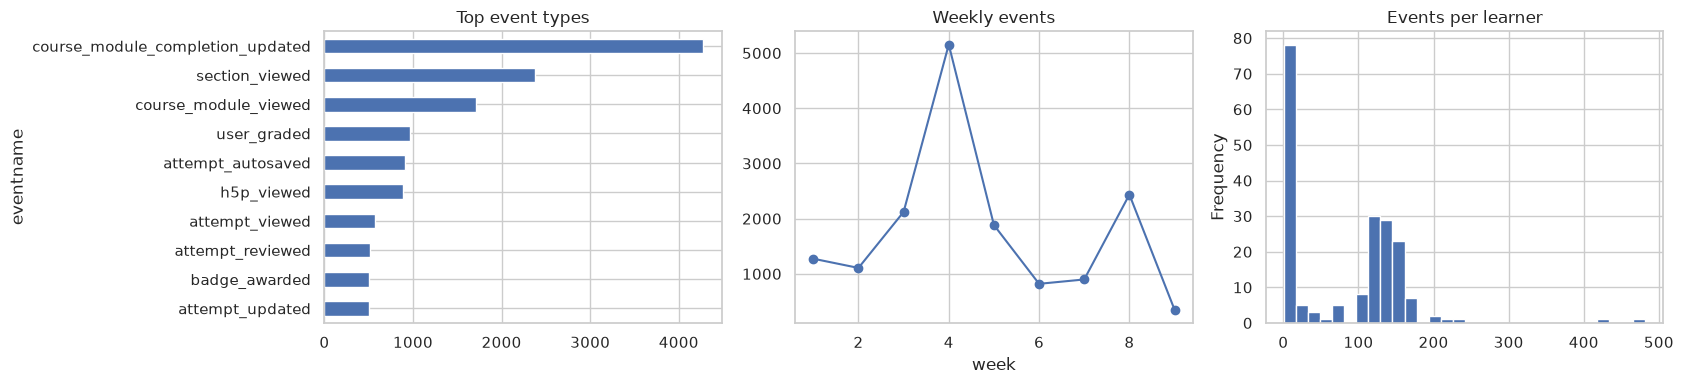

Panel shape: (1755, 19); weeks: 9; learners: 195


In [ ]:
# 2. EDA AND LEARNER-WEEK FEATURE ENGINEERING
course_start = int(ae['timecreated'].min())
ae = ae.copy(); ae['week'] = ((ae['timecreated'] - course_start) // (7 * 24 * 3600) + 1).clip(lower=1).astype(int)
max_week = int(ae.week.max())
ae_weekly = ae.groupby(['userid','week']).agg(total_events=('id','count'), unique_components=('component','nunique'), unique_actions=('action','nunique')).reset_index()
if 'timemodified.1' in grades.columns:
    grades = grades.copy()
    grades['timemodified.1'] = pd.to_numeric(grades['timemodified.1'], errors='coerce')
    grades = grades.dropna(subset=['timemodified.1', 'userid'])
    grades['week'] = ((grades['timemodified.1'] - course_start) // (7 * 24 * 3600) + 1).clip(lower=1).astype(int)
    grade_weekly = grades.dropna(subset=['finalgrade']).groupby(['userid','week']).agg(grade_records=('userid','size'), avg_grade=('finalgrade','mean'), max_grade=('finalgrade','max')).reset_index()
else:
    grade_weekly = pd.DataFrame(columns=['userid','week','grade_records','avg_grade','max_grade'])
if len(video) > 50 and {'start','stop'}.issubset(video.columns):
    video = video.copy()
    video['start'] = pd.to_numeric(video['start'], errors='coerce')
    video['stop'] = pd.to_numeric(video['stop'], errors='coerce')
    video = video.dropna(subset=['start', 'stop', 'userid'])
    video['week'] = ((video['start'] - course_start) // (7 * 24 * 3600) + 1).clip(lower=1).astype(int)
    video['watch_time'] = (video['stop'] - video['start']).clip(lower=0)
    video_weekly = video.groupby(['userid','week']).agg(video_events=('id','count'), total_watch_time=('watch_time','sum'), unique_videos=('videoid','nunique')).reset_index()
else:
    video_weekly = pd.DataFrame(columns=['userid','week','video_events','total_watch_time','unique_videos'])
grid = pd.MultiIndex.from_product([all_learners, range(1, max_week + 1)], names=['userid','week']).to_frame(index=False)
panel = grid.merge(ae_weekly, on=['userid','week'], how='left').merge(grade_weekly, on=['userid','week'], how='left').merge(video_weekly, on=['userid','week'], how='left').fillna(0)
for col in ['total_events','unique_components','unique_actions','grade_records','video_events','total_watch_time','unique_videos']: panel[col] = panel[col].fillna(0)
panel = panel.sort_values(['userid','week'])
panel['activity_delta'] = panel.groupby('userid').total_events.diff().fillna(0)
panel['activity_slope'] = panel['activity_delta']
panel['cumulative_events'] = panel.groupby('userid').total_events.cumsum()
panel['weeks_active'] = panel.groupby('userid').total_events.transform(lambda x: (x > 0).cumsum())
panel['activity_consistency'] = panel.groupby('userid').total_events.transform(lambda x: x.rolling(3, min_periods=1).std().fillna(0))
panel['early_warning_score'] = 0.6 * (panel.total_events == 0).astype(float) + 0.4 * (panel.activity_slope < 0).astype(float)
panel['completion_rate'] = (panel.grade_records / max(len(activities), 1)).clip(0, 1)
panel = panel.merge(labels, on='userid', how='left')
panel.to_parquet(PROCESSED_ROOT / f'learner_week_panel_{COURSE_ID}.parquet', index=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ae.eventname.astype(str).str.split('\\').str[-1].value_counts().head(10).sort_values().plot.barh(ax=axes[0], title='Top event types')
ae.groupby('week').size().plot(ax=axes[1], marker='o', title='Weekly events')
ae.groupby('userid').size().plot.hist(ax=axes[2], bins=30, title='Events per learner')
plt.tight_layout(); plt.savefig(RESULTS_ROOT / f'02_eda_{COURSE_ID}.png', dpi=180); plt.show()
print(f'Panel shape: {panel.shape}; weeks: {max_week}; learners: {panel.userid.nunique()}')

## 4. Decline-Pattern Discovery

This section summarises each learner's activity trajectory across the course.

First, we calculate learner-level measures such as average activity, average change in activity, number of inactive weeks, and average early-warning score. We create simple rule-based labels as an interpretable baseline.

We then use K-means clustering to group learners with similar engagement behaviour. The resulting groups are given understandable names such as Stable, Gradual Decline, Early Disengagement, or Sporadic. These labels are useful for studying which types of learners are more likely to complete the course and which groups may need support.

### Notes

Learner trajectories are created by aggregating the learner-week panel to one row per `userid`. The selected trajectory columns are standardised with `StandardScaler` before clustering. Several K-means values are tested, and the implementation selects a data-dependent value before fitting `KMeans(..., n_init=10, random_state=42)`. Cluster IDs are then ordered using mean slope, mean activity, and inactive-week statistics and mapped to human-readable pattern labels.

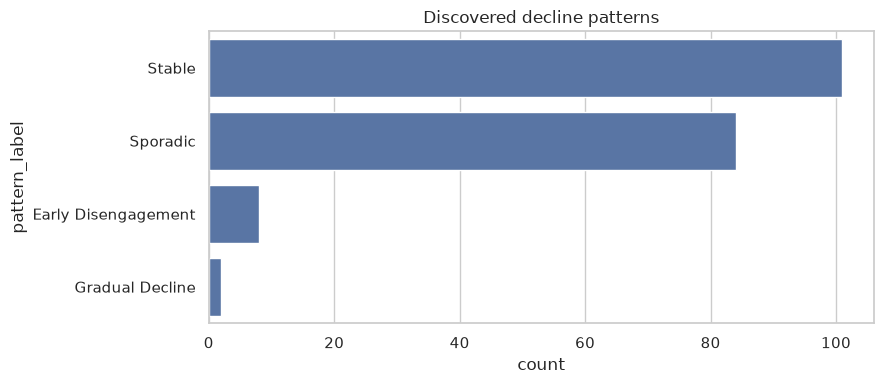

pattern_label
Stable                 101
Sporadic                84
Early Disengagement      8
Gradual Decline          2


In [ ]:
# 3. DECLINE-PATTERN DISCOVERY
traj = panel.groupby('userid').agg(total_events_mean=('total_events','mean'), activity_slope_mean=('activity_slope','mean'), activity_slope_last=('activity_slope','last'), zero_weeks=('total_events', lambda x: int((x == 0).sum())), early_warning_mean=('early_warning_score','mean'), weeks_active_max=('weeks_active','max'), unique_actions_mean=('unique_actions','mean'), total_events_sum=('total_events','sum')).reset_index()
traj['rule_label'] = np.select([ (traj.activity_slope_mean >= -0.5) & (traj.zero_weeks <= 1), (traj.activity_slope_mean < -0.5) & (traj.zero_weeks <= max_week/2), traj.zero_weeks >= max_week/2], ['Stable','Gradual Decline','Early Disengagement'], default='Sporadic')
feature_cols = ['total_events_mean','activity_slope_mean','zero_weeks','early_warning_mean','weeks_active_max','unique_actions_mean']
X = StandardScaler().fit_transform(traj[feature_cols].fillna(0))
candidate_k = range(2, min(6, len(traj)-1) + 1)
scores = {}
for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X); scores[k] = model.inertia_
best_k = min(scores, key=scores.get) if len(scores) == 1 else max(2, min(scores, key=lambda k: scores[k] / k))
km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10); traj['cluster'] = km.fit_predict(X)
cluster_stats = traj.groupby('cluster').agg(slope=('activity_slope_mean','mean'), events=('total_events_mean','mean'), zeros=('zero_weeks','mean')).sort_values(['slope','events'])
ordered = list(cluster_stats.index)
cluster_names = {}
for rank, cluster in enumerate(ordered): cluster_names[cluster] = ['Early Disengagement','Gradual Decline','Sporadic','Stable'][min(rank, 3)]
traj['pattern_label'] = traj.cluster.map(cluster_names)
traj[['userid','rule_label','cluster','pattern_label']].to_parquet(PROCESSED_ROOT / f'learner_patterns_{COURSE_ID}.parquet', index=False)
fig, ax = plt.subplots(figsize=(9, 4)); sns.countplot(data=traj, y='pattern_label', order=traj.pattern_label.value_counts().index, ax=ax); ax.set_title('Discovered decline patterns'); plt.tight_layout(); plt.savefig(RESULTS_ROOT / f'03_patterns_{COURSE_ID}.png', dpi=180); plt.show()
print(traj.pattern_label.value_counts().to_string())

## 5. Pattern-to-Course-Structure Analysis

This section connects learner behaviour with the design of the course.

We describe each course section using its workload, assessment density, and interactive-content density. We then use section-view events to estimate how far each learner reached in the course and what type of content they encountered.

Finally, association-rule mining searches for combinations of course-structure conditions that appear together with specific decline patterns. These results do not prove causation, but they show useful relationships that can guide course redesign. Group statistics and association rules are saved for the final report.

### Notes

Section features are calculated with grouped counts and proportions over activity types. Learner exposure is built from events whose target is `section` and whose object table is `course_sections`; each learner's maximum reached section is converted to a progress ratio. Continuous exposure variables are rank-based quantile-binned into Low, Medium, High, or Uniform categories. The analysis creates a one-hot basket and applies `mlxtend.frequent_patterns.apriori`, followed by `association_rules` filtered by confidence. Lift, support, and confidence are retained as rule-strength measures.

In [ ]:
# 4. PATTERN-TO-COURSE-STRUCTURE ANALYSIS
# Normalize section identifiers before joining activity metadata to section-view events.
activities = activities.copy()
activities['section'] = pd.to_numeric(activities['section'], errors='coerce')
section_features = activities.dropna(subset=['section']).groupby('section').agg(workload=('name','count')).reset_index().sort_values('section').reset_index(drop=True)
section_features['order'] = np.arange(len(section_features))
types = activities.groupby('section')['name'].agg(assessment_density=lambda s: s.astype(str).str.lower().isin(['quiz','feedback']).mean(), interactive_density=lambda s: s.astype(str).str.lower().eq('h5pactivity').mean(), content_density=lambda s: s.astype(str).str.lower().isin(['resource','url','label']).mean()).reset_index()
section_features = section_features.merge(types, on='section', how='left')
if {'target','objecttable','objectid'}.issubset(ae.columns):
    views = ae[(ae.target == 'section') & (ae.objecttable == 'course_sections')].copy(); views['section'] = pd.to_numeric(views.objectid, errors='coerce'); views = views.dropna(subset=['section']); views['section'] = views.section.astype(section_features.section.dtype); views['week'] = ((views.timecreated - course_start) // (7*24*3600) + 1).clip(lower=1); views = views.groupby(['userid','section']).week.min().reset_index()
else:
    views = pd.DataFrame(columns=['userid','section','week'])
exposure = views.merge(section_features, on='section', how='left').groupby('userid').agg(sections_reached=('section','nunique'), max_order_reached=('order','max'), mean_workload_exposure=('workload','mean'), mean_assessment_exposure=('assessment_density','mean'), mean_interactive_exposure=('interactive_density','mean')).reset_index()
exposure = pd.DataFrame({'userid': all_learners}).merge(exposure, on='userid', how='left').fillna(0); total_sections = max(len(section_features), 1); exposure['progress_ratio'] = (exposure.max_order_reached + 1).clip(lower=0) / total_sections
merged = traj[['userid','pattern_label']].merge(exposure, on='userid', how='left')
group_stats = merged.groupby('pattern_label').agg(n=('userid','size'), mean_progress_ratio=('progress_ratio','mean'), mean_workload=('mean_workload_exposure','mean')).reset_index()
group_stats.to_csv(RESULTS_ROOT / f'04_pattern_structure_group_stats_{COURSE_ID}.csv', index=False)
def qbin(s, name):
    if s.nunique() <= 1: return pd.Series([f'{name}=Uniform'] * len(s), index=s.index)
    return pd.qcut(s.rank(method='first'), q=min(3, s.nunique()), labels=['Low','Medium','High'][:min(3,s.nunique())]).astype(str).radd(name + '=')
items = pd.DataFrame({'userid': exposure.userid, 'progress': qbin(exposure.progress_ratio, 'progress'), 'workload': qbin(exposure.mean_workload_exposure, 'workload'), 'assessment': qbin(exposure.mean_assessment_exposure, 'assessment'), 'interactive': qbin(exposure.mean_interactive_exposure, 'interactive')}).merge(traj[['userid','pattern_label']], on='userid', how='left').drop(columns='userid')
basket = pd.get_dummies(items.stack()).groupby(level=0).max().astype(bool)
freq = apriori(basket, min_support=0.05, use_colnames=True)
if freq.empty: rules = pd.DataFrame(columns=['antecedents','consequents','support','confidence','lift'])
else:
    rules = association_rules(freq, metric='confidence', min_threshold=0.5); rules['antecedents'] = rules.antecedents.apply(lambda x: ', '.join(sorted(x))); rules['consequents'] = rules.consequents.apply(lambda x: ', '.join(sorted(x))); rules = rules.sort_values('lift', ascending=False)[['antecedents','consequents','support','confidence','lift']]
rules.to_csv(RESULTS_ROOT / 'pattern_structure_report.csv', index=False)
print(group_stats.to_string(index=False)); print(f'Association rules: {len(rules)}')

      pattern_label   n  mean_progress_ratio  mean_workload
Early Disengagement   8             0.975000       8.697917
    Gradual Decline   2             0.600000       4.375000
           Sporadic  84             0.409524       9.948413
             Stable 101             0.976238       8.754125
Association rules: 628


## 6. Stage A: Early Decline Prediction

This model tries to identify learners who are likely to show a declining engagement pattern while there is still time to help them.

Only information from weeks 1 to 4 is used as input. This is important because using later activity could reveal the answer in advance and make the evaluation unrealistic. The features include event counts, actions, grades, video activity, activity changes, and warning scores.

Several models are trained and compared. The best model is selected using PR-AUC, which is useful when the two outcome groups are not equally large. The selected model produces an early decline-risk score for every learner.

### Notes

The first four weeks are aggregated into one feature row per learner. A stratified `train_test_split` creates training and test partitions, and `StandardScaler` is fitted only on the training features. `SMOTE` is applied only to the training data when both classes have enough examples. Logistic Regression and Random Forest models are trained, and performance is measured with precision, recall, F1, and `average_precision_score` for PR-AUC. The best architecture is refit to produce `decline_risk_score` values.

In [ ]:
# 5. STAGE A: EARLY DECLINE PREDICTION FROM WEEKS 1-4
# Predict decline after week 4; this do not use the full-course pattern label as the target.
early = panel[panel.week.isin(STAGE_A_WEEKS)].sort_values(['userid','week'])
future = panel[panel.week > max(STAGE_A_WEEKS)]
sum_cols = ['total_events','unique_components','unique_actions','grade_records','video_events','total_watch_time','unique_videos']
mean_cols = ['activity_slope','activity_consistency','early_warning_score']
stage_a = early.groupby('userid')[sum_cols].sum().add_suffix('_sum').join(early.groupby('userid')[mean_cols].mean().add_suffix('_mean')).reset_index()
last = early.groupby('userid').last()[['cumulative_events','weeks_active']].add_suffix('_week4').reset_index(); stage_a = stage_a.merge(last, on='userid')

# Define the outcome only from weeks 5 onward.
early_baseline = early.groupby('userid').total_events.mean().rename('early_events_mean')
future_summary = future.groupby('userid').agg(future_events_mean=('total_events','mean'), future_active_weeks=('total_events', lambda x: int((x > 0).sum()))).reset_index()
future_target = pd.DataFrame({'userid': all_learners}).merge(early_baseline, on='userid', how='left').merge(future_summary, on='userid', how='left').fillna(0)
future_target['declining'] = ((future_target.future_active_weeks == 0) | ((future_target.early_events_mean > 0) & (future_target.future_events_mean < 0.5 * future_target.early_events_mean))).astype(int)
stage_a = stage_a.merge(future_target[['userid','declining']], on='userid').merge(traj[['userid','pattern_label']], on='userid').merge(labels, on='userid')
stage_a_features = [c for c in stage_a.columns if c.endswith(('_sum','_mean','_week4'))]
Xa, ya = stage_a[stage_a_features].fillna(0), stage_a.declining
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.3, random_state=RANDOM_STATE, stratify=ya)
scaler_a = StandardScaler(); Xa_train_s = scaler_a.fit_transform(Xa_train); Xa_test_s = scaler_a.transform(Xa_test)
sampler_a = SMOTE(random_state=RANDOM_STATE); Xa_res, ya_res = sampler_a.fit_resample(Xa_train_s, ya_train) if ya_train.nunique() == 2 and ya_train.value_counts().min() >= 2 else (Xa_train_s, ya_train)
models = {'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE), 'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE)}
def score_models(model_dict, Xtr, ytr, Xte, yte):
    rows = {}; fitted = {}
    for name, model in model_dict.items():
        model.fit(Xtr, ytr); prob = model.predict_proba(Xte)[:,1]; pred = (prob >= 0.5).astype(int); fitted[name] = model; rows[name] = {'precision': precision_score(yte,pred,zero_division=0), 'recall': recall_score(yte,pred,zero_division=0), 'f1': f1_score(yte,pred,zero_division=0), 'pr_auc': average_precision_score(yte,prob)}
    return pd.DataFrame(rows).T.reset_index(names='model'), fitted
stage_a_report, stage_a_models = score_models(models, Xa_res, ya_res, Xa_test_s, ya_test); stage_a_report = stage_a_report.sort_values('pr_auc', ascending=False).reset_index(drop=True); stage_a_report.to_csv(RESULTS_ROOT / 'stage_a_model_report.csv', index=False)
best_a = stage_a_report.iloc[0].model; final_a = models[best_a]; full_scaled = scaler_a.fit_transform(Xa); full_res, full_y = sampler_a.fit_resample(full_scaled, ya) if ya.value_counts().min() >= 2 else (full_scaled, ya); final_a.fit(full_res, full_y); decline_scores = final_a.predict_proba(scaler_a.transform(Xa))[:,1]
risk = pd.DataFrame({'userid': stage_a.userid, 'decline_risk_score': decline_scores}).merge(traj[['userid','pattern_label']], on='userid'); risk.to_parquet(PROCESSED_ROOT / f'decline_risk_scores_{COURSE_ID}.parquet', index=False)
print(f'Future decline target: {ya.sum():,}/{len(ya):,} learners ({ya.mean():.1%})')
print(stage_a_report.to_string(index=False)); print(f'Best Stage A model: {best_a}')

Future decline target: 117/195 learners (60.0%)
             model  precision   recall       f1   pr_auc
      RandomForest   0.861111 0.885714 0.873239 0.954053
LogisticRegression   0.880000 0.628571 0.733333 0.922230
Best Stage A model: RandomForest


## 7. Stage B: Completion and Dropout Prediction

This section predicts whether a learner will complete the course.

Two feature sets are compared. B1 uses only early behavioural information. B2 adds the Stage A decline-risk score and the learner's engagement-pattern indicators. Comparing B1 and B2 shows whether the early decline analysis adds useful information for completion prediction.

The data is split into training and test sets. Scaling and SMOTE are applied only to the training data so that the test results remain an honest estimate of performance. Precision, recall, F1, and PR-AUC are reported for each model.

### Notes

The B1 feature matrix contains the early behavioural features, while B2 adds the Stage A risk score and one-hot encoded pattern columns created with `pd.get_dummies(..., drop_first=True)`. Each feature set receives its own stratified train/test split, scaler, and SMOTE operation. The same model-scoring function evaluates Logistic Regression and Random Forest, allowing the ablation comparison to focus on the value of the additional Stage A signal.

In [ ]:
# 6. STAGE B: DROPOUT/COMPLETION PREDICTION WITH AND WITHOUT STAGE A SIGNAL
base = stage_a.drop(columns=['declining','pattern_label','completed'], errors='ignore').merge(labels, on='userid').merge(risk[['userid','decline_risk_score','pattern_label']], on='userid')
pattern_dummies = pd.get_dummies(base['pattern_label'], prefix='pattern', drop_first=True, dtype=float); base = pd.concat([base.drop(columns='pattern_label'), pattern_dummies], axis=1)
b1_cols = [c for c in stage_a_features if c in base.columns]; b2_cols = b1_cols + ['decline_risk_score'] + list(pattern_dummies.columns)
def run_stage_b(data, columns, label):
    Xb, yb = data[columns].fillna(0), data.completed
    Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.3, random_state=RANDOM_STATE, stratify=yb)
    scaler = StandardScaler(); Xtr_s, Xte_s = scaler.fit_transform(Xtr), scaler.transform(Xte); sampler = SMOTE(random_state=RANDOM_STATE); Xres, yres = sampler.fit_resample(Xtr_s,ytr) if ytr.value_counts().min() >= 2 else (Xtr_s,ytr)
    report, fitted = score_models({'LogisticRegression': LogisticRegression(max_iter=2000,class_weight='balanced',random_state=RANDOM_STATE), 'RandomForest': RandomForestClassifier(n_estimators=300,class_weight='balanced',random_state=RANDOM_STATE)}, Xres,yres,Xte_s,yte); report['feature_set'] = label
    return report, fitted, scaler
report_b1, models_b1, scaler_b1 = run_stage_b(base, b1_cols, 'B1 base behavior'); report_b2, models_b2, scaler_b2 = run_stage_b(base, b2_cols, 'B2 base + Stage A signal'); comparison = pd.concat([report_b1,report_b2], ignore_index=True); comparison.to_csv(RESULTS_ROOT / 'stage_b_model_comparison.csv', index=False)
b2 = base[['userid','completed'] + b2_cols].copy(); b2.to_parquet(PROCESSED_ROOT / f'stage_b_features_{COURSE_ID}.parquet', index=False)
print(comparison[['feature_set','model','precision','recall','f1','pr_auc']].to_string(index=False)); print(f'Best B2 model: {report_b2.sort_values("pr_auc", ascending=False).iloc[0].model}')

             feature_set              model  precision   recall       f1   pr_auc
        B1 base behavior LogisticRegression   0.904762 0.655172 0.760000 0.875962
        B1 base behavior       RandomForest   0.880000 0.758621 0.814815 0.905410
B2 base + Stage A signal LogisticRegression   0.828571 1.000000 0.906250 0.792571
B2 base + Stage A signal       RandomForest   0.828571 1.000000 0.906250 0.815901
Best B2 model: RandomForest


## 8. SHAP Explainability and Recommendations

This final section explains which features influenced the best completion model.

SHAP values show whether a feature pushed a prediction toward completion or toward dropout, and how strongly it contributed. This makes the model easier to inspect instead of treating it as a black box.

The notebook then combines the model findings with the course-structure results. It creates practical recommendations such as adding early progress checks, dividing very heavy sections into smaller units, and placing more low-stakes assessments throughout the course. The recommendations are saved as a Markdown report in the output folder.

### Notes

The best B2 model is refit on the full scaled feature set, with SMOTE used for the fitting data when possible. `shap.TreeExplainer` is used for Random Forest because it supports efficient tree explanations; the generic `shap.Explainer` is used as a fallback for other models. Mean absolute SHAP values rank global feature importance, while correlations between feature values and SHAP values indicate direction. The final Markdown report is generated with `Path.write_text()` from live pattern, structure, and model results.

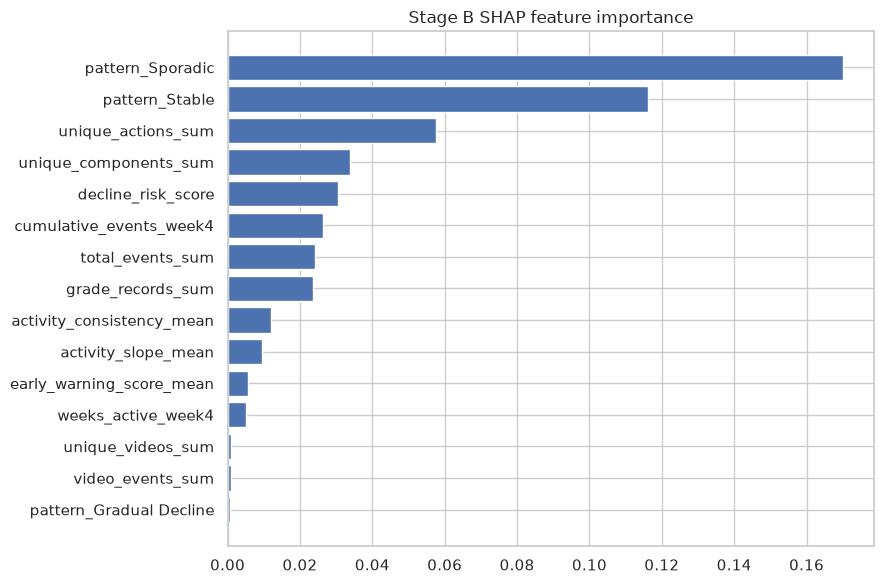

Best Stage B model: RandomForest
Recommendations written to: /content/mooc_pipeline_output/results/recommendations.md
Pipeline complete. All outputs are under: /content/mooc_pipeline_output


In [ ]:
# 7. SHAP EXPLAINABILITY AND COURSE-DESIGN RECOMMENDATIONS
best_b2 = report_b2.sort_values('pr_auc', ascending=False).iloc[0].model; Xfull = b2[b2_cols].fillna(0); yfull = b2.completed
scaler = StandardScaler(); Xfull_s = pd.DataFrame(scaler.fit_transform(Xfull), columns=b2_cols); sampler = SMOTE(random_state=RANDOM_STATE); Xres, yres = sampler.fit_resample(Xfull_s,yfull) if yfull.value_counts().min() >= 2 else (Xfull_s,yfull)
final_b = {'LogisticRegression': LogisticRegression(max_iter=2000,class_weight='balanced',random_state=RANDOM_STATE), 'RandomForest': RandomForestClassifier(n_estimators=300,class_weight='balanced',random_state=RANDOM_STATE)}[best_b2]; final_b.fit(Xres,yres)
try:
    import shap
    explainer = shap.TreeExplainer(final_b) if best_b2 == 'RandomForest' else shap.Explainer(final_b.predict_proba, Xfull_s)
    shap_result = explainer(Xfull_s); shap_matrix = shap_result.values[...,1] if getattr(shap_result.values,'ndim',2) == 3 else shap_result.values
    importance = pd.DataFrame({'feature': b2_cols, 'mean_abs_shap': np.abs(shap_matrix).mean(axis=0), 'direction_corr': [np.corrcoef(shap_matrix[:,i], Xfull_s.iloc[:,i])[0,1] if Xfull_s.iloc[:,i].std() else 0 for i in range(len(b2_cols))]}).sort_values('mean_abs_shap', ascending=False)
    importance.to_csv(RESULTS_ROOT / f'shap_feature_importance_{COURSE_ID}.csv', index=False)
    plt.figure(figsize=(9,6)); top = importance.head(15).sort_values('mean_abs_shap'); plt.barh(top.feature, top.mean_abs_shap); plt.title('Stage B SHAP feature importance'); plt.tight_layout(); plt.savefig(RESULTS_ROOT / f'07_shap_summary_{COURSE_ID}.png', dpi=180); plt.show()
except Exception as exc:
    importance = pd.DataFrame({'feature': b2_cols, 'model_importance': getattr(final_b, 'feature_importances_', np.zeros(len(b2_cols)))}) .sort_values('model_importance', ascending=False); print(f'SHAP unavailable; model importance used: {exc}')

top_pattern = traj.pattern_label.value_counts().index[0]; lowest_progress = group_stats.sort_values('mean_progress_ratio').iloc[0]; recommendations = [f'Split the heaviest course sections into smaller units with visible milestones.', f'Add low-stakes assessment checkpoints in sections with high workload and low assessment density.', f'Use an early progress check around week 2-4 to identify learners with high decline risk.', f'Balance workload across sections and monitor the pattern with the lowest mean progress ({lowest_progress.pattern_label}, {lowest_progress.mean_progress_ratio:.1%}).']
report_path = RESULTS_ROOT / 'recommendations.md'; report_path.write_text('# Course-Design Recommendations\n\n' + '\n'.join(f'{i}. {text}' for i,text in enumerate(recommendations,1)) + '\n', encoding='utf-8')
print(f'Best Stage B model: {best_b2}'); print(f'Recommendations written to: {report_path}'); print('Pipeline complete. All outputs are under:', OUTPUT_ROOT.resolve())